In [1]:
import pandas as pd
from pathlib import Path

data_path = Path("data")

print("CSV faylları:")
for file in sorted(data_path.glob("*.csv")):
    print(file.name)

CSV faylları:
olist_customers_dataset.csv
olist_order_items_dataset.csv
olist_order_reviews_dataset.csv
olist_orders_dataset.csv
olist_products_dataset.csv
olist_sellers_dataset.csv
product_category_name_translation.csv


In [2]:

import pandas as pd

files = {
    "orders": "data/olist_orders_dataset.csv",
    "order_items": "data/olist_order_items_dataset.csv",
    "products": "data/olist_products_dataset.csv",
    "reviews": "data/olist_order_reviews_dataset.csv",
    "sellers": "data/olist_sellers_dataset.csv",
    "customers": "data/olist_customers_dataset.csv",
    "category_translation": "data/product_category_name_translation.csv"
}

for name, path in files.items():
    df = pd.read_csv(path)
    print(f"\n{name.upper()} — sətir sayı: {df.shape[0]}, sütun sayı: {df.shape[1]}")
    print("Sütunlar:", df.columns.tolist())



ORDERS — sətir sayı: 99441, sütun sayı: 8
Sütunlar: ['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']

ORDER_ITEMS — sətir sayı: 112650, sütun sayı: 7
Sütunlar: ['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']

PRODUCTS — sətir sayı: 32951, sütun sayı: 9
Sütunlar: ['product_id', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']

REVIEWS — sətir sayı: 99224, sütun sayı: 7
Sütunlar: ['review_id', 'order_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'review_answer_timestamp']

SELLERS — sətir sayı: 3095, sütun sayı: 4
Sütunlar: ['seller_id', 'seller_zip_code_prefix', 'seller_city', 'seller_state']

CUSTOMERS — sətir

In [3]:
checks = {
    "orders": ("data/olist_orders_dataset.csv", ["order_id"]),
    "order_items": ("data/olist_order_items_dataset.csv", ["order_id", "order_item_id"]),
    "products": ("data/olist_products_dataset.csv", ["product_id"]),
    "reviews": ("data/olist_order_reviews_dataset.csv", ["review_id"]),
    "sellers": ("data/olist_sellers_dataset.csv", ["seller_id"]),
    "customers": ("data/olist_customers_dataset.csv", ["customer_id"]),
    "category_translation": (
        "data/product_category_name_translation.csv",
        ["product_category_name"]
    )
}

for table, (path, keys) in checks.items():
    df = pd.read_csv(path)
    duplicate_count = df.duplicated(subset=keys).sum()
    null_count = df[keys].isna().any(axis=1).sum()

    print(f"{table}:")
    print(f"  Təkrarlanan açar sətirləri: {duplicate_count}")
    print(f"  Açarı boş olan sətirlər: {null_count}")

orders:
  Təkrarlanan açar sətirləri: 0
  Açarı boş olan sətirlər: 0
order_items:
  Təkrarlanan açar sətirləri: 0
  Açarı boş olan sətirlər: 0
products:
  Təkrarlanan açar sətirləri: 0
  Açarı boş olan sətirlər: 0
reviews:
  Təkrarlanan açar sətirləri: 814
  Açarı boş olan sətirlər: 0
sellers:
  Təkrarlanan açar sətirləri: 0
  Açarı boş olan sətirlər: 0
customers:
  Təkrarlanan açar sətirləri: 0
  Açarı boş olan sətirlər: 0
category_translation:
  Təkrarlanan açar sətirləri: 0
  Açarı boş olan sətirlər: 0


In [4]:

%%writefile queries.sql

-- 1. Customers: hər müştəri üçün unikal customer_id
CREATE TABLE IF NOT EXISTS customers (
    customer_id TEXT PRIMARY KEY,
    customer_unique_id TEXT,
    customer_zip_code_prefix TEXT,
    customer_city TEXT,
    customer_state TEXT
);

-- 2. Orders: hər sifariş üçün unikal order_id
CREATE TABLE IF NOT EXISTS orders (
    order_id TEXT PRIMARY KEY,
    customer_id TEXT NOT NULL,
    order_status TEXT,
    order_purchase_timestamp TEXT,
    order_approved_at TEXT,
    order_delivered_carrier_date TEXT,
    order_delivered_customer_date TEXT,
    order_estimated_delivery_date TEXT,
    FOREIGN KEY (customer_id) REFERENCES customers(customer_id)
);

-- 3. Sellers: hər satıcı üçün unikal seller_id
CREATE TABLE IF NOT EXISTS sellers (
    seller_id TEXT PRIMARY KEY,
    seller_zip_code_prefix TEXT,
    seller_city TEXT,
    seller_state TEXT
);

-- 4. Product category translations
CREATE TABLE IF NOT EXISTS category_translation (
    product_category_name TEXT PRIMARY KEY,
    product_category_name_english TEXT
);

-- 5. Products: hər məhsul üçün unikal product_id
CREATE TABLE IF NOT EXISTS products (
    product_id TEXT PRIMARY KEY,
    product_category_name TEXT,
    product_name_lenght INTEGER,
    product_description_lenght INTEGER,
    product_photos_qty INTEGER,
    product_weight_g REAL,
    product_length_cm REAL,
    product_height_cm REAL,
    product_width_cm REAL,
    FOREIGN KEY (product_category_name)
        REFERENCES category_translation(product_category_name)
);

-- 6. Order items: bir sifarişdə bir neçə məhsul ola bilər
CREATE TABLE IF NOT EXISTS order_items (
    order_id TEXT NOT NULL,
    order_item_id INTEGER NOT NULL,
    product_id TEXT NOT NULL,
    seller_id TEXT NOT NULL,
    shipping_limit_date TEXT,
    price REAL,
    freight_value REAL,
    PRIMARY KEY (order_id, order_item_id),
    FOREIGN KEY (order_id) REFERENCES orders(order_id),
    FOREIGN KEY (product_id) REFERENCES products(product_id),
    FOREIGN KEY (seller_id) REFERENCES sellers(seller_id)
);

-- 7. Reviews: review_id təkrarlandığı üçün texniki ID istifadə edirik
CREATE TABLE IF NOT EXISTS reviews (
    review_row_id INTEGER PRIMARY KEY AUTOINCREMENT,
    review_id TEXT,
    order_id TEXT NOT NULL,
    review_score INTEGER,
    review_comment_title TEXT,
    review_comment_message TEXT,
    review_creation_date TEXT,
    review_answer_timestamp TEXT,
    FOREIGN KEY (order_id) REFERENCES orders(order_id)
);


Overwriting queries.sql


In [5]:
from pathlib import Path

sql_path = Path("queries.sql")
sql_text = sql_path.read_text(encoding="utf-8")

sql_text = sql_text.replace(
    """    FOREIGN KEY (product_category_name)
        REFERENCES category_translation(product_category_name)
""",
    ""
)

sql_path.write_text(sql_text, encoding="utf-8")

print("Kateqoriya əlaqəsi düzəldildi.")

Kateqoriya əlaqəsi düzəldildi.


In [6]:

import sqlite3
from pathlib import Path

db_path = Path("ecommerce_kpi.db")
sql_path = Path("queries.sql")

with sqlite3.connect(db_path) as conn:
    conn.execute("PRAGMA foreign_keys = ON")
    conn.executescript(sql_path.read_text(encoding="utf-8"))

print("SQL cədvəlləri uğurla yaradıldı.")


OperationalError: near ")": syntax error

In [ ]:
for number, line in enumerate(
    Path("queries.sql").read_text(encoding="utf-8").splitlines(),
    start=1
):
    print(f"{number}: {line}")

In [ ]:
sql_path = Path("queries.sql")
sql_text = sql_path.read_text(encoding="utf-8")

sql_text = sql_text.replace(
    "product_width_cm REAL,\n);",
    "product_width_cm REAL\n);"
)

sql_path.write_text(sql_text, encoding="utf-8")

print("Vergül düzəldildi.")

In [ ]:
with sqlite3.connect("ecommerce_kpi.db") as conn:
    conn.execute("PRAGMA foreign_keys = ON")
    conn.executescript(
        Path("queries.sql").read_text(encoding="utf-8")
    )

print("SQL cədvəlləri uğurla yaradıldı.")

In [ ]:
with sqlite3.connect("ecommerce_kpi.db") as conn:
    tables = pd.read_sql_query(
        """
        SELECT name
        FROM sqlite_master
        WHERE type = 'table'
        ORDER BY name;
        """,
        conn
    )

display(tables)

In [ ]:

import csv
import sqlite3
from pathlib import Path

db_path = Path("ecommerce_kpi.db")
data_path = Path("data")

table_files = {
    "customers": "olist_customers_dataset.csv",
    "orders": "olist_orders_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "category_translation": "product_category_name_translation.csv",
    "products": "olist_products_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv"
}

with sqlite3.connect(db_path) as conn:
    conn.execute("PRAGMA foreign_keys = ON")

    for table, filename in table_files.items():
        file_path = data_path / filename

        with open(file_path, "r", encoding="utf-8-sig", newline="") as file:
            reader = csv.DictReader(file)
            columns = reader.fieldnames

            placeholders = ", ".join(["?"] * len(columns))
            column_names = ", ".join(f'"{col}"' for col in columns)

            # Reviews cədvəlində texniki ID avtomatik yaranır.
            if table == "reviews":
                column_names = ", ".join(f'"{col}"' for col in columns)

            insert_sql = (
                f'INSERT INTO "{table}" ({column_names}) '
                f'VALUES ({placeholders})'
            )

            rows = (
                [row[col] if row[col] != "" else None for col in columns]
                for row in reader
            )

            conn.executemany(insert_sql, rows)

        print(f"{table}: məlumatlar yükləndi.")

print("Bütün CSV məlumatları bazaya yükləndi.")


In [ ]:

expected_tables = [
    "customers",
    "orders",
    "sellers",
    "category_translation",
    "products",
    "order_items",
    "reviews"
]

with sqlite3.connect("ecommerce_kpi.db") as conn:
    for table in expected_tables:
        count = pd.read_sql_query(
            f'SELECT COUNT(*) AS total_rows FROM "{table}"',
            conn
        ).iloc[0]["total_rows"]

        print(f"{table}: {count:,} sətir")


In [ ]:

with sqlite3.connect("ecommerce_kpi.db") as conn:
    conn.execute("PRAGMA foreign_keys = ON")

    for table in [
        "orders",
        "order_items",
        "products",
        "reviews"
    ]:
        result = conn.execute(
            f'PRAGMA foreign_key_list("{table}")'
        ).fetchall()

        print(f"\n{table.upper()} — Foreign Keys:")
        for row in result:
            print(f"  {row[3]} -> {row[2]}.{row[4]}")


In [ ]:

with sqlite3.connect("ecommerce_kpi.db") as conn:
    checks = {
        "Sifarişi olmayan order_items": """
            SELECT COUNT(*)
            FROM order_items oi
            LEFT JOIN orders o ON oi.order_id = o.order_id
            WHERE o.order_id IS NULL
        """,
        "Məhsulu olmayan order_items": """
            SELECT COUNT(*)
            FROM order_items oi
            LEFT JOIN products p ON oi.product_id = p.product_id
            WHERE p.product_id IS NULL
        """,
        "Satıcısı olmayan order_items": """
            SELECT COUNT(*)
            FROM order_items oi
            LEFT JOIN sellers s ON oi.seller_id = s.seller_id
            WHERE s.seller_id IS NULL
        """
    }

    for label, query in checks.items():
        count = conn.execute(query).fetchone()[0]
        print(f"{label}: {count}")


In [ ]:

from pathlib import Path

query_q1 = r"""

-- Q1: Analytical base
-- Grain: one row per order item.
-- Reviews are aggregated to one row per order to avoid row multiplication.

DROP VIEW IF EXISTS analytical_base;

CREATE VIEW analytical_base AS
WITH review_per_order AS (
    SELECT
        order_id,
        AVG(review_score) AS review_score,
        COUNT(*) AS review_count
    FROM reviews
    GROUP BY order_id
)
SELECT
    o.order_id,
    o.customer_id,
    o.order_status,
    o.order_purchase_timestamp,
    o.order_delivered_customer_date,
    o.order_estimated_delivery_date,
    oi.order_item_id,
    oi.product_id,
    oi.seller_id,
    oi.price,
    oi.freight_value,
    p.product_category_name,
    ct.product_category_name_english,
    r.review_score,
    r.review_count
FROM orders o
INNER JOIN order_items oi
    ON o.order_id = oi.order_id
INNER JOIN products p
    ON oi.product_id = p.product_id
LEFT JOIN category_translation ct
    ON p.product_category_name = ct.product_category_name
LEFT JOIN review_per_order r
    ON o.order_id = r.order_id;

"""

with Path("queries.sql").open("a", encoding="utf-8") as file:
    file.write("\n" + query_q1)

print("Q1 sorğusu queries.sql faylına əlavə edildi.")


In [ ]:

with sqlite3.connect("ecommerce_kpi.db") as conn:
    conn.execute("PRAGMA foreign_keys = ON")
    conn.executescript("""
        DROP VIEW IF EXISTS analytical_base;

        CREATE VIEW analytical_base AS
        WITH review_per_order AS (
            SELECT
                order_id,
                AVG(review_score) AS review_score,
                COUNT(*) AS review_count
            FROM reviews
            GROUP BY order_id
        )
        SELECT
            o.order_id,
            o.customer_id,
            o.order_status,
            o.order_purchase_timestamp,
            o.order_delivered_customer_date,
            o.order_estimated_delivery_date,
            oi.order_item_id,
            oi.product_id,
            oi.seller_id,
            oi.price,
            oi.freight_value,
            p.product_category_name,
            ct.product_category_name_english,
            r.review_score,
            r.review_count
        FROM orders o
        INNER JOIN order_items oi
            ON o.order_id = oi.order_id
        INNER JOIN products p
            ON oi.product_id = p.product_id
        LEFT JOIN category_translation ct
            ON p.product_category_name = ct.product_category_name
        LEFT JOIN (
            SELECT
                order_id,
                AVG(review_score) AS review_score,
                COUNT(*) AS review_count
            FROM reviews
            GROUP BY order_id
        ) r ON o.order_id = r.order_id;
    """)

    result = pd.read_sql_query("""
        SELECT
            COUNT(*) AS total_rows,
            COUNT(DISTINCT order_id) AS distinct_orders,
            SUM(price) AS total_revenue
        FROM analytical_base;
    """, conn)

display(result)


In [ ]:

with sqlite3.connect("ecommerce_kpi.db") as conn:
    reconciliation = pd.read_sql_query("""
        SELECT
            (SELECT SUM(price)
             FROM order_items) AS direct_revenue,

            (SELECT SUM(price)
             FROM analytical_base) AS joined_revenue,

            (SELECT SUM(price)
             FROM analytical_base)
            -
            (SELECT SUM(price)
             FROM order_items) AS revenue_difference;
    """, conn)

display(reconciliation)


In [ ]:

q3_sql = """

-- Q3: Revenue reconciliation
-- Compare source revenue with analytical base revenue.
-- Expected difference: 0.

SELECT
    (SELECT SUM(price) FROM order_items) AS direct_revenue,
    (SELECT SUM(price) FROM analytical_base) AS joined_revenue,
    (SELECT SUM(price) FROM analytical_base)
      - (SELECT SUM(price) FROM order_items) AS revenue_difference;

"""

with Path("queries.sql").open("a", encoding="utf-8") as file:
    file.write("\n" + q3_sql)

print("Q3 reconciliation sorğusu queries.sql faylına əlavə edildi.")


In [36]:

q4_sql = """
WITH order_revenue AS (
    SELECT
        order_id,
        SUM(price) AS order_value
    FROM order_items
    GROUP BY order_id
),
delivered_orders AS (
    SELECT
        order_id,
        order_delivered_customer_date,
        order_purchase_timestamp
    FROM orders
    WHERE order_status = 'delivered'
      AND order_delivered_customer_date IS NOT NULL
      AND order_purchase_timestamp IS NOT NULL
),
order_reviews AS (
    SELECT
        order_id,
        AVG(review_score) AS review_score
    FROM reviews
    GROUP BY order_id
)
SELECT
    (SELECT SUM(price) FROM order_items) AS total_revenue,
    (SELECT AVG(order_value) FROM order_revenue) AS aov,
    (
        SELECT AVG(
            julianday(order_delivered_customer_date)
            - julianday(order_purchase_timestamp)
        )
        FROM delivered_orders
    ) AS avg_delivery_days,
    (
        SELECT AVG(r.review_score)
        FROM delivered_orders d
        JOIN order_reviews r ON d.order_id = r.order_id
    ) AS avg_review_score;
"""

with sqlite3.connect("ecommerce_kpi.db") as conn:
    q4_results = pd.read_sql_query(q4_sql, conn)

display(q4_results)


,total_revenue,aov,avg_delivery_days,avg_review_score
0,13591643.7,137.754076,12.558217,4.156158


In [ ]:
print(q4_results.T.to_string(header=False))

In [ ]:

q4_section = """

-- Q4: Core KPIs
-- Revenue and AOV cover all orders containing items.
-- Delivery days and review score cover delivered orders only.

WITH order_revenue AS (
    SELECT
        order_id,
        SUM(price) AS order_value
    FROM order_items
    GROUP BY order_id
),
delivered_orders AS (
    SELECT
        order_id,
        order_delivered_customer_date,
        order_purchase_timestamp
    FROM orders
    WHERE order_status = 'delivered'
      AND order_delivered_customer_date IS NOT NULL
      AND order_purchase_timestamp IS NOT NULL
),
order_reviews AS (
    SELECT
        order_id,
        AVG(review_score) AS review_score
    FROM reviews
    GROUP BY order_id
)
SELECT
    (SELECT SUM(price) FROM order_items) AS total_revenue,
    (SELECT AVG(order_value) FROM order_revenue) AS aov,
    (
        SELECT AVG(
            julianday(order_delivered_customer_date)
            - julianday(order_purchase_timestamp)
        )
        FROM delivered_orders
    ) AS avg_delivery_days,
    (
        SELECT AVG(r.review_score)
        FROM delivered_orders d
        JOIN order_reviews r ON d.order_id = r.order_id
    ) AS avg_review_score;

"""

with Path("queries.sql").open("a", encoding="utf-8") as file:
    file.write("\n" + q4_section)

print("Q4 core KPI sorğusu queries.sql faylına əlavə edildi.")


In [ ]:

q5_sql = """
SELECT
    COALESCE(
        product_category_name_english,
        product_category_name,
        'Unknown'
    ) AS category,
    COUNT(*) AS items_sold,
    COUNT(DISTINCT order_id) AS order_count,
    ROUND(SUM(price), 2) AS total_revenue,
    ROUND(AVG(price), 2) AS avg_item_price,
    ROUND(SUM(freight_value), 2) AS total_freight
FROM analytical_base
GROUP BY
    COALESCE(
        product_category_name_english,
        product_category_name,
        'Unknown'
    )
ORDER BY total_revenue DESC;
"""

with sqlite3.connect("ecommerce_kpi.db") as conn:
    q5_results = pd.read_sql_query(q5_sql, conn)

display(q5_results.head(10))


In [ ]:

q5_section = """

-- Q5: Category-level KPIs
-- Revenue, item volume, distinct orders, average item price, and freight.

SELECT
    COALESCE(
        product_category_name_english,
        product_category_name,
        'Unknown'
    ) AS category,
    COUNT(*) AS items_sold,
    COUNT(DISTINCT order_id) AS order_count,
    ROUND(SUM(price), 2) AS total_revenue,
    ROUND(AVG(price), 2) AS avg_item_price,
    ROUND(SUM(freight_value), 2) AS total_freight
FROM analytical_base
GROUP BY
    COALESCE(
        product_category_name_english,
        product_category_name,
        'Unknown'
    )
ORDER BY total_revenue DESC;

"""

with Path("queries.sql").open("a", encoding="utf-8") as file:
    file.write("\n" + q5_section)

print("Q5 category KPI sorğusu queries.sql faylına əlavə edildi.")


In [ ]:

q6_sql = """
WITH monthly_kpis AS (
    SELECT
        strftime('%Y-%m', order_purchase_timestamp) AS month,
        COUNT(DISTINCT order_id) AS order_count,
        COUNT(*) AS items_sold,
        SUM(price) AS total_revenue,
        SUM(freight_value) AS total_freight
    FROM analytical_base
    WHERE order_purchase_timestamp IS NOT NULL
    GROUP BY strftime('%Y-%m', order_purchase_timestamp)
)
SELECT
    month,
    order_count,
    items_sold,
    ROUND(total_revenue, 2) AS total_revenue,
    ROUND(total_freight, 2) AS total_freight,
    ROUND(
        (total_revenue - LAG(total_revenue) OVER (ORDER BY month))
        * 100.0
        / NULLIF(LAG(total_revenue) OVER (ORDER BY month), 0),
        2
    ) AS revenue_growth_pct
FROM monthly_kpis
ORDER BY month;
"""

with sqlite3.connect("ecommerce_kpi.db") as conn:
    q6_results = pd.read_sql_query(q6_sql, conn)

display(q6_results)


In [ ]:

q6_section = """

-- Q6: Monthly revenue and order trends
-- LAG compares each available month with the previous available month.

WITH monthly_kpis AS (
    SELECT
        strftime('%Y-%m', order_purchase_timestamp) AS month,
        COUNT(DISTINCT order_id) AS order_count,
        COUNT(*) AS items_sold,
        SUM(price) AS total_revenue,
        SUM(freight_value) AS total_freight
    FROM analytical_base
    WHERE order_purchase_timestamp IS NOT NULL
    GROUP BY strftime('%Y-%m', order_purchase_timestamp)
)
SELECT
    month,
    order_count,
    items_sold,
    ROUND(total_revenue, 2) AS total_revenue,
    ROUND(total_freight, 2) AS total_freight,
    ROUND(
        (
            total_revenue
            - LAG(total_revenue) OVER (ORDER BY month)
        ) * 100.0
        / NULLIF(
            LAG(total_revenue) OVER (ORDER BY month),
            0
        ),
        2
    ) AS revenue_growth_pct
FROM monthly_kpis
ORDER BY month;

"""

with Path("queries.sql").open("a", encoding="utf-8") as file:
    file.write("\n" + q6_section)

print("Q6 monthly KPI sorğusu queries.sql faylına əlavə edildi.")


In [ ]:

q7_sql = """
SELECT
    seller_id,
    COUNT(DISTINCT order_id) AS order_count,
    COUNT(*) AS items_sold,
    ROUND(SUM(price), 2) AS total_revenue,
    ROUND(AVG(price), 2) AS avg_item_price,
    ROUND(SUM(freight_value), 2) AS total_freight,
    ROUND(
        SUM(price) * 100.0
        / SUM(SUM(price)) OVER (),
        2
    ) AS revenue_share_pct,
    RANK() OVER (
        ORDER BY SUM(price) DESC
    ) AS revenue_rank
FROM analytical_base
GROUP BY seller_id
ORDER BY total_revenue DESC
LIMIT 10;
"""

with sqlite3.connect("ecommerce_kpi.db") as conn:
    q7_results = pd.read_sql_query(q7_sql, conn)

display(q7_results)


In [ ]:

q7_section = """

-- Q7: Seller performance and revenue ranking

SELECT
    seller_id,
    COUNT(DISTINCT order_id) AS order_count,
    COUNT(*) AS items_sold,
    ROUND(SUM(price), 2) AS total_revenue,
    ROUND(AVG(price), 2) AS avg_item_price,
    ROUND(SUM(freight_value), 2) AS total_freight,
    ROUND(
        SUM(price) * 100.0 / SUM(SUM(price)) OVER (),
        2
    ) AS revenue_share_pct,
    RANK() OVER (
        ORDER BY SUM(price) DESC
    ) AS revenue_rank
FROM analytical_base
GROUP BY seller_id
ORDER BY total_revenue DESC
LIMIT 10;

"""

with Path("queries.sql").open("a", encoding="utf-8") as file:
    file.write("\n" + q7_section)

print("Q7 seller KPI sorğusu queries.sql faylına əlavə edildi.")


In [ ]:

q8_sql = """
WITH category_kpis AS (
    SELECT
        COALESCE(
            product_category_name_english,
            product_category_name,
            'Unknown'
        ) AS category,
        COUNT(*) AS items_sold,
        COUNT(DISTINCT order_id) AS order_count,
        SUM(price) AS total_revenue,
        AVG(price) AS avg_item_price
    FROM analytical_base
    GROUP BY
        COALESCE(
            product_category_name_english,
            product_category_name,
            'Unknown'
        )
    HAVING COUNT(*) >= 100
),
ranked_categories AS (
    SELECT
        *,
        RANK() OVER (ORDER BY total_revenue DESC) AS revenue_rank,
        RANK() OVER (ORDER BY total_revenue ASC) AS lowest_revenue_rank
    FROM category_kpis
)
SELECT
    category,
    items_sold,
    order_count,
    ROUND(total_revenue, 2) AS total_revenue,
    ROUND(avg_item_price, 2) AS avg_item_price,
    revenue_rank,
    lowest_revenue_rank
FROM ranked_categories
WHERE revenue_rank <= 10
   OR lowest_revenue_rank <= 10
ORDER BY total_revenue DESC;
"""

with sqlite3.connect("ecommerce_kpi.db") as conn:
    q8_results = pd.read_sql_query(q8_sql, conn)

display(q8_results)


In [ ]:

q8_section = """

-- Q8: Highest and lowest revenue categories
-- Only categories with at least 100 sold items are included.

WITH category_kpis AS (
    SELECT
        COALESCE(
            product_category_name_english,
            product_category_name,
            'Unknown'
        ) AS category,
        COUNT(*) AS items_sold,
        COUNT(DISTINCT order_id) AS order_count,
        SUM(price) AS total_revenue,
        AVG(price) AS avg_item_price
    FROM analytical_base
    GROUP BY
        COALESCE(
            product_category_name_english,
            product_category_name,
            'Unknown'
        )
    HAVING COUNT(*) >= 100
),
ranked_categories AS (
    SELECT
        *,
        RANK() OVER (ORDER BY total_revenue DESC) AS revenue_rank,
        RANK() OVER (ORDER BY total_revenue ASC) AS lowest_revenue_rank
    FROM category_kpis
)
SELECT
    category,
    items_sold,
    order_count,
    ROUND(total_revenue, 2) AS total_revenue,
    ROUND(avg_item_price, 2) AS avg_item_price,
    revenue_rank,
    lowest_revenue_rank
FROM ranked_categories
WHERE revenue_rank <= 10
   OR lowest_revenue_rank <= 10
ORDER BY total_revenue DESC;

"""

with Path("queries.sql").open("a", encoding="utf-8") as file:
    file.write("\n" + q8_section)

print("Q8 category ranking sorğusu queries.sql faylına əlavə edildi.")


In [41]:

q9_sql = """
WITH delivery_metrics AS (
    SELECT
        order_id,
        order_status,
        order_delivered_customer_date,
        order_estimated_delivery_date,
        CASE
            WHEN order_status = 'delivered'
             AND order_delivered_customer_date IS NOT NULL
             AND order_estimated_delivery_date IS NOT NULL
             AND julianday(order_delivered_customer_date)
                 <= julianday(order_estimated_delivery_date)
            THEN 1
            ELSE 0
        END AS on_time_flag,
        CASE
            WHEN order_status = 'delivered'
             AND order_delivered_customer_date IS NOT NULL
             AND order_estimated_delivery_date IS NOT NULL
            THEN 1
            ELSE 0
        END AS eligible_delivery_flag
    FROM orders
)
SELECT
    COUNT(*) AS total_orders,
    SUM(eligible_delivery_flag) AS delivered_orders_with_dates,
    SUM(on_time_flag) AS on_time_delivered_orders,
    ROUND(
        100.0 * SUM(on_time_flag)
        / NULLIF(SUM(eligible_delivery_flag), 0),
        2
    ) AS on_time_delivery_rate_pct
FROM delivery_metrics;
"""

with sqlite3.connect("ecommerce_kpi.db") as conn:
    q9_results = pd.read_sql_query(q9_sql, conn)

display(q9_results)


,total_orders,delivered_orders_with_dates,on_time_delivered_orders,on_time_delivery_rate_pct
0,99441,96470,88644,91.89


In [ ]:

q9_section = """

-- Q9: Bonus KPI - On-time delivery rate
-- Eligible population: delivered orders with both actual and estimated dates.
-- On-time means actual delivery date <= estimated delivery date.

WITH delivery_metrics AS (
    SELECT
        order_id,
        order_status,
        order_delivered_customer_date,
        order_estimated_delivery_date,
        CASE
            WHEN order_status = 'delivered'
             AND order_delivered_customer_date IS NOT NULL
             AND order_estimated_delivery_date IS NOT NULL
             AND julianday(order_delivered_customer_date)
                 <= julianday(order_estimated_delivery_date)
            THEN 1
            ELSE 0
        END AS on_time_flag,
        CASE
            WHEN order_status = 'delivered'
             AND order_delivered_customer_date IS NOT NULL
             AND order_estimated_delivery_date IS NOT NULL
            THEN 1
            ELSE 0
        END AS eligible_delivery_flag
    FROM orders
)
SELECT
    COUNT(*) AS total_orders,
    SUM(eligible_delivery_flag) AS delivered_orders_with_dates,
    SUM(on_time_flag) AS on_time_delivered_orders,
    ROUND(
        100.0 * SUM(on_time_flag)
        / NULLIF(SUM(eligible_delivery_flag), 0),
        2
    ) AS on_time_delivery_rate_pct
FROM delivery_metrics;

"""

with Path("queries.sql").open("a", encoding="utf-8") as file:
    file.write("\n" + q9_section)

print("Q9 on-time delivery sorğusu queries.sql faylına əlavə edildi.")


In [ ]:

q10_sql = """
WITH orders_without_reviews AS (
    SELECT
        o.order_id
    FROM orders o
    LEFT JOIN reviews r
        ON o.order_id = r.order_id
    WHERE r.order_id IS NULL
)
SELECT
    (SELECT COUNT(*) FROM orders) AS total_orders,
    (SELECT COUNT(*) FROM orders_without_reviews)
        AS orders_without_reviews,
    ROUND(
        100.0 * (SELECT COUNT(*) FROM orders_without_reviews)
        / NULLIF((SELECT COUNT(*) FROM orders), 0),
        2
    ) AS no_review_share_pct;
"""

with sqlite3.connect("ecommerce_kpi.db") as conn:
    q10_results = pd.read_sql_query(q10_sql, conn)

display(q10_results)


In [42]:

q10_section = """

-- Q10: Bonus KPI - Orders without reviews
-- Anti-join identifies orders with no matching review rows.

WITH orders_without_reviews AS (
    SELECT o.order_id
    FROM orders o
    LEFT JOIN reviews r
        ON o.order_id = r.order_id
    WHERE r.order_id IS NULL
)
SELECT
    (SELECT COUNT(*) FROM orders) AS total_orders,
    (SELECT COUNT(*) FROM orders_without_reviews)
        AS orders_without_reviews,
    ROUND(
        100.0 * (SELECT COUNT(*) FROM orders_without_reviews)
        / NULLIF((SELECT COUNT(*) FROM orders), 0),
        2
    ) AS no_review_share_pct;

"""

with Path("queries.sql").open("a", encoding="utf-8") as file:
    file.write("\n" + q10_section)

print("Q10 orders without reviews sorğusu queries.sql faylına əlavə edildi.")


Q10 orders without reviews sorğusu queries.sql faylına əlavə edildi.


In [43]:
with sqlite3.connect("ecommerce_kpi.db") as conn:
    q10_results = pd.read_sql_query(q10_section, conn)

display(q10_results)

,total_orders,orders_without_reviews,no_review_share_pct
0,99441,768,0.77


In [ ]:

q11_sql = """
WITH item_metrics AS (
    SELECT
        order_id,
        order_item_id,
        COALESCE(
            product_category_name_english,
            product_category_name,
            'Unknown'
        ) AS category,
        price,
        freight_value,
        CASE
            WHEN price > 0
             AND freight_value >= price * 0.5
            THEN 1
            ELSE 0
        END AS margin_erosion_flag
    FROM analytical_base
)
SELECT
    category,
    COUNT(*) AS items_sold,
    ROUND(SUM(price), 2) AS total_revenue,
    ROUND(SUM(freight_value), 2) AS total_freight,
    ROUND(
        100.0 * SUM(freight_value)
        / NULLIF(SUM(price), 0),
        2
    ) AS freight_cost_ratio_pct,
    SUM(margin_erosion_flag) AS high_freight_risk_items,
    ROUND(
        100.0 * SUM(margin_erosion_flag) / COUNT(*),
        2
    ) AS high_freight_risk_items_pct
FROM item_metrics
GROUP BY category
ORDER BY freight_cost_ratio_pct DESC;
"""

with sqlite3.connect("ecommerce_kpi.db") as conn:
    q11_results = pd.read_sql_query(q11_sql, conn)

display(q11_results.head(10))


In [ ]:

q11_section = """

-- Q11: Bonus KPI - Freight cost ratio and margin erosion risk
-- Risk flag: freight_value >= 50% of item price.
-- This is a risk proxy, not a true profit-margin calculation.

WITH item_metrics AS (
    SELECT
        order_id,
        order_item_id,
        COALESCE(
            product_category_name_english,
            product_category_name,
            'Unknown'
        ) AS category,
        price,
        freight_value,
        CASE
            WHEN price > 0
             AND freight_value >= price * 0.5
            THEN 1
            ELSE 0
        END AS margin_erosion_flag
    FROM analytical_base
)
SELECT
    category,
    COUNT(*) AS items_sold,
    ROUND(SUM(price), 2) AS total_revenue,
    ROUND(SUM(freight_value), 2) AS total_freight,
    ROUND(
        100.0 * SUM(freight_value)
        / NULLIF(SUM(price), 0),
        2
    ) AS freight_cost_ratio_pct,
    SUM(margin_erosion_flag) AS high_freight_risk_items,
    ROUND(
        100.0 * SUM(margin_erosion_flag) / COUNT(*),
        2
    ) AS high_freight_risk_items_pct
FROM item_metrics
GROUP BY category
ORDER BY freight_cost_ratio_pct DESC;

"""

with Path("queries.sql").open("a", encoding="utf-8") as file:
    file.write("\n" + q11_section)

print("Q11 freight cost ratio sorğusu queries.sql faylına əlavə edildi.")


In [ ]:

q12_sql = """
WITH monthly_category_revenue AS (
    SELECT
        strftime('%Y-%m', order_purchase_timestamp) AS month,
        COALESCE(
            product_category_name_english,
            product_category_name,
            'Unknown'
        ) AS category,
        SUM(price) AS category_revenue
    FROM analytical_base
    WHERE order_purchase_timestamp IS NOT NULL
    GROUP BY
        strftime('%Y-%m', order_purchase_timestamp),
        COALESCE(
            product_category_name_english,
            product_category_name,
            'Unknown'
        )
),
category_share AS (
    SELECT
        month,
        category,
        category_revenue,
        SUM(category_revenue) OVER (
            PARTITION BY month
        ) AS monthly_total_revenue,
        RANK() OVER (
            PARTITION BY month
            ORDER BY category_revenue DESC
        ) AS category_revenue_rank
    FROM monthly_category_revenue
)
SELECT
    month,
    category,
    ROUND(category_revenue, 2) AS category_revenue,
    ROUND(monthly_total_revenue, 2) AS monthly_total_revenue,
    ROUND(
        100.0 * category_revenue
        / NULLIF(monthly_total_revenue, 0),
        2
    ) AS monthly_revenue_share_pct,
    category_revenue_rank
FROM category_share
ORDER BY month, category_revenue_rank;
"""

with sqlite3.connect("ecommerce_kpi.db") as conn:
    q12_results = pd.read_sql_query(q12_sql, conn)

display(q12_results.head(15))


In [ ]:

q12_section = """

-- Q12: Bonus KPI - Monthly category revenue share
-- Window functions calculate monthly totals and category ranks.

WITH monthly_category_revenue AS (
    SELECT
        strftime('%Y-%m', order_purchase_timestamp) AS month,
        COALESCE(
            product_category_name_english,
            product_category_name,
            'Unknown'
        ) AS category,
        SUM(price) AS category_revenue
    FROM analytical_base
    WHERE order_purchase_timestamp IS NOT NULL
    GROUP BY
        strftime('%Y-%m', order_purchase_timestamp),
        COALESCE(
            product_category_name_english,
            product_category_name,
            'Unknown'
        )
),
category_share AS (
    SELECT
        month,
        category,
        category_revenue,
        SUM(category_revenue) OVER (
            PARTITION BY month
        ) AS monthly_total_revenue,
        RANK() OVER (
            PARTITION BY month
            ORDER BY category_revenue DESC
        ) AS category_revenue_rank
    FROM monthly_category_revenue
)
SELECT
    month,
    category,
    ROUND(category_revenue, 2) AS category_revenue,
    ROUND(monthly_total_revenue, 2) AS monthly_total_revenue,
    ROUND(
        100.0 * category_revenue
        / NULLIF(monthly_total_revenue, 0),
        2
    ) AS monthly_revenue_share_pct,
    category_revenue_rank
FROM category_share
ORDER BY month, category_revenue_rank;

"""

with Path("queries.sql").open("a", encoding="utf-8") as file:
    file.write("\n" + q12_section)

print("Q12 monthly category revenue share sorğusu queries.sql faylına əlavə edildi.")


In [45]:

correlation_sql = """
SELECT
    COALESCE(
        product_category_name_english,
        product_category_name,
        'Unknown'
    ) AS category,
    COUNT(*) AS items_sold,
    ROUND(SUM(price), 2) AS total_revenue,
    ROUND(SUM(freight_value), 2) AS total_freight,
    ROUND(AVG(price), 2) AS avg_item_price,
    ROUND(AVG(review_score), 2) AS avg_review_score
FROM analytical_base
GROUP BY
    COALESCE(
        product_category_name_english,
        product_category_name,
        'Unknown'
    )
HAVING COUNT(*) >= 100
ORDER BY total_revenue DESC;
"""

with sqlite3.connect("ecommerce_kpi.db") as conn:
    correlation_df = pd.read_sql_query(correlation_sql, conn)

display(correlation_df.head(10))
print("Kateqoriyaların ümumi sayı:", len(correlation_df))


,category,items_sold,total_revenue,total_freight,avg_item_price,avg_review_score
0,health_beauty,9670,1258681.34,182566.73,130.16,4.14
1,watches_gifts,5991,1205005.68,100535.93,201.14,4.02
2,bed_bath_table,11115,1036988.68,204693.04,93.30,3.90
3,sports_leisure,8641,988048.97,168607.51,114.34,4.11
4,computers_accessories,7827,911954.32,147318.08,116.51,3.93
5,furniture_decor,8334,729762.49,172749.30,87.56,3.91
6,cool_stuff,3796,635290.85,84039.10,167.36,4.15
7,housewares,6964,632248.66,146149.11,90.79,4.05
8,auto,4235,592720.11,92664.21,139.96,4.06
9,garden_tools,4347,485256.46,98962.75,111.63,4.05


Kateqoriyaların ümumi sayı: 54


In [46]:

revenue_freight_corr = correlation_df[
    ["total_revenue", "total_freight"]
].corr(method="pearson").iloc[0, 1]

print(
    f"Revenue və freight arasındakı korrelyasiya: "
    f"{revenue_freight_corr:.4f}"
)


Revenue və freight arasındakı korrelyasiya: 0.9358


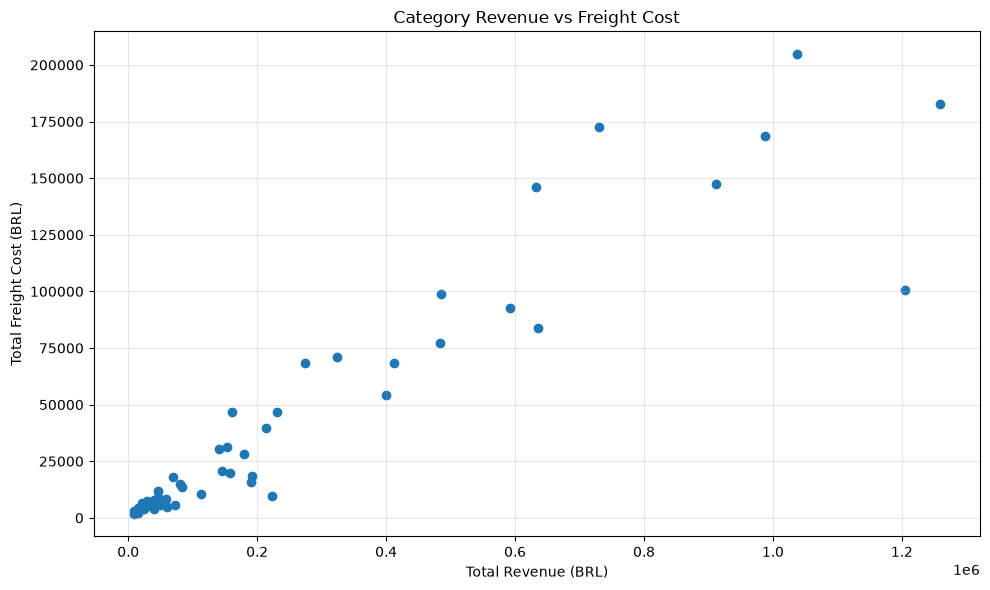

In [47]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(
    correlation_df["total_revenue"],
    correlation_df["total_freight"]
)

plt.title("Category Revenue vs Freight Cost")
plt.xlabel("Total Revenue (BRL)")
plt.ylabel("Total Freight Cost (BRL)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


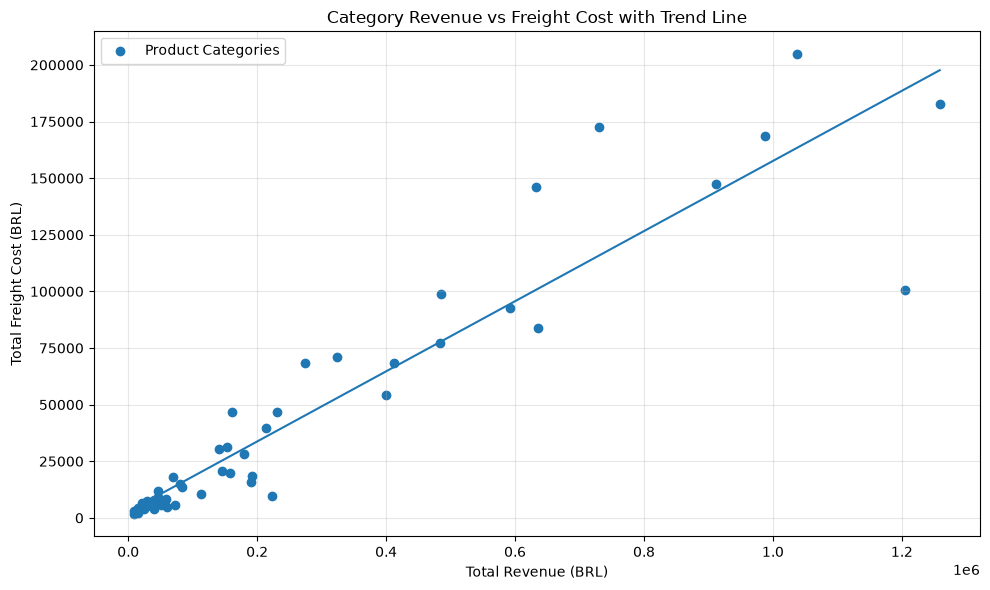

In [48]:
import numpy as np
import matplotlib.pyplot as plt

x = correlation_df["total_revenue"]
y = correlation_df["total_freight"]

plt.figure(figsize=(10, 6))
plt.scatter(x, y, label="Product Categories")

trend = np.polyfit(x, y, 1)
trend_line = np.poly1d(trend)

plt.plot(x, trend_line(x))
plt.title("Category Revenue vs Freight Cost with Trend Line")
plt.xlabel("Total Revenue (BRL)")
plt.ylabel("Total Freight Cost (BRL)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

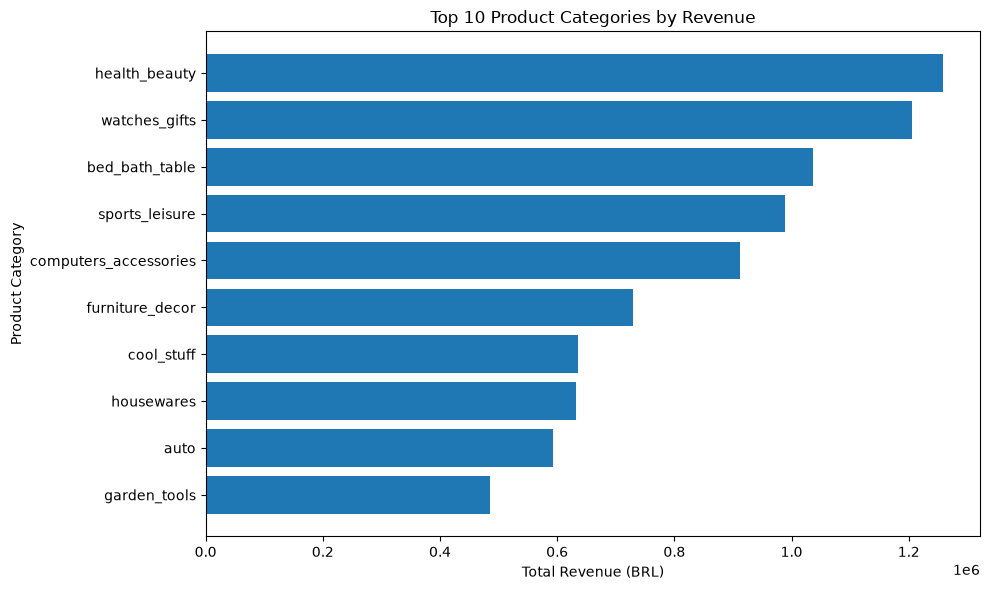

In [49]:
category_top10 = correlation_df.nlargest(10, "total_revenue").sort_values(
    "total_revenue", ascending=True
)

plt.figure(figsize=(10, 6))
plt.barh(category_top10["category"], category_top10["total_revenue"])
plt.title("Top 10 Product Categories by Revenue")
plt.xlabel("Total Revenue (BRL)")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

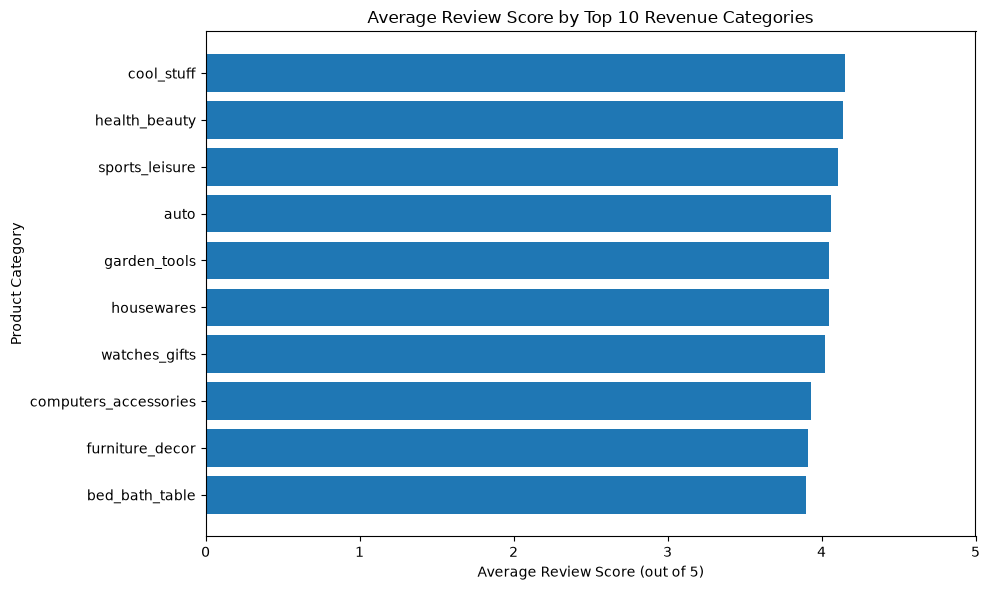

In [50]:
category_reviews = correlation_df.nlargest(10, "total_revenue").sort_values(
    "avg_review_score", ascending=True
)

plt.figure(figsize=(10, 6))
plt.barh(category_reviews["category"], category_reviews["avg_review_score"])
plt.title("Average Review Score by Top 10 Revenue Categories")
plt.xlabel("Average Review Score (out of 5)")
plt.ylabel("Product Category")
plt.xlim(0, 5)
plt.tight_layout()
plt.show()

In [ ]:

correlation_section = """

-- Q13: Correlation analysis - Category revenue vs freight cost
SELECT
    COALESCE(
        product_category_name_english,
        product_category_name,
        'Unknown'
    ) AS category,
    COUNT(*) AS items_sold,
    SUM(price) AS total_revenue,
    SUM(freight_value) AS total_freight,
    AVG(price) AS avg_item_price,
    AVG(review_score) AS avg_review_score
FROM analytical_base
GROUP BY
    COALESCE(
        product_category_name_english,
        product_category_name,
        'Unknown'
    )
HAVING COUNT(*) >= 100
ORDER BY total_revenue DESC;

"""

with Path("queries.sql").open("a", encoding="utf-8") as file:
    file.write("\n" + correlation_section)

print("Q13 correlation analysis sorğusu queries.sql faylına əlavə edildi.")


In [ ]:

from pathlib import Path

note_content = """# End-to-End KPI Framework for E-Commerce Operations

## 1. Project Overview

This project analyzes the Brazilian Olist e-commerce dataset using SQLite, SQL, and Jupyter Notebook. The goal is to build an end-to-end KPI framework for evaluating revenue, orders, delivery performance, product categories, sellers, reviews, and freight costs.

## 2. Tools Used

- SQLite
- SQL
- Jupyter Notebook
- Python
- pandas
- Matplotlib

## 3. Database Tables

The database contains seven tables:

- `orders` — order status and purchase, approval, delivery, and estimated delivery dates.
- `order_items` — products purchased in each order, seller, price, and freight cost.
- `products` — product information and category.
- `category_translation` — Portuguese-to-English product category names.
- `sellers` — seller identifiers and location information.
- `customers` — customer identifiers and location information.
- `reviews` — customer review scores and review dates.

## 4. Data Model and Join Strategy

- `orders.order_id` joins to `order_items.order_id`.
- `order_items.product_id` joins to `products.product_id`.
- `order_items.seller_id` joins to `sellers.seller_id`.
- `orders.customer_id` joins to `customers.customer_id`.
- `reviews.order_id` joins to `orders.order_id`.
- Product categories join to `category_translation` using `product_category_name`.

The analytical base view uses one row per order item. Reviews are aggregated by order before joining so that multiple review rows do not multiply item-level revenue. LEFT JOIN is used for category translation to preserve categories without an English translation.

## 5. Revenue Reconciliation

The direct revenue calculation and the analytical-view revenue calculation both returned BRL 13,591,643.70. The difference was BRL 0.00, confirming that the analytical joins did not inflate revenue.

## 6. Key KPIs and Findings

1. **Total revenue:** BRL 13,591,643.70.
2. **Average order value (AOV):** approximately BRL 137.75.
3. **Average delivery time:** approximately 12.56 days for delivered orders with available delivery dates.
4. **Average review score:** approximately 4.16.
5. **On-time delivery rate:** 91.89% among delivered orders with both actual and estimated delivery dates.
6. **Orders without reviews:** 768 orders, representing 0.77% of all orders.
7. **Top revenue category:** `health_beauty`, with BRL 1,258,681.34 in revenue.
8. **Highest monthly category share in the displayed September 2016 results:** `health_beauty` represented 50.48% of that month's revenue.
9. **Revenue-freight correlation:** Pearson correlation was 0.9358 across the 54 product categories included in the analysis.
10. **Freight risk indicator:** categories were flagged when freight cost was at least 50% of item price. This is a risk proxy, not a true profit-margin calculation.

## 7. SQL Analysis Included

The `queries.sql` file contains the database schema, analytical base view, revenue reconciliation, core KPIs, category KPIs, monthly KPIs, seller KPIs, category rankings, on-time delivery rate, orders without reviews, freight-cost risk analysis, monthly category revenue share, and the category-level data used for correlation analysis.

Window functions are used for ranking, monthly revenue comparisons, and category revenue shares.

## 8. Visualization

A scatter plot compares total category revenue with total category freight cost. The correlation of 0.9358 indicates a strong positive association, but it does not prove that higher revenue causes higher freight costs.

## 9. Limitations

- Freight cost is not the same as total operating cost.
- The freight risk indicator does not account for product purchase costs, commissions, or other expenses.
- Delivery performance is calculated only for delivered orders with both actual and estimated delivery dates.
- Correlation indicates association, not causation.
- Some product categories do not have an English translation.

## 10. Conclusion

The project demonstrates how SQL can be used to create a reusable KPI framework for e-commerce operations. The analysis provides insights into revenue, product categories, seller performance, delivery reliability, customer reviews, and freight-cost risks.
"""

Path("note.md").write_text(note_content, encoding="utf-8")

print("note.md faylı yaradıldı.")
print("Faylın yeri:", Path("note.md").resolve())


In [ ]:

from pathlib import Path

required_files = [
    "queries.sql",
    "kpi_analysis.ipynb",
    "ecommerce_kpi.db",
    "note.md"
]

for filename in required_files:
    file_path = Path(filename)
    status = "OK" if file_path.exists() else "MISSING"
    print(f"{status}: {filename}")


In [ ]:

with sqlite3.connect("ecommerce_kpi.db") as conn:
    db_objects = pd.read_sql_query("""
        SELECT name, type
        FROM sqlite_master
        WHERE type IN ('table', 'view')
        ORDER BY type, name;
    """, conn)

display(db_objects)

with sqlite3.connect("ecommerce_kpi.db") as conn:
    view_check = pd.read_sql_query("""
        SELECT
            COUNT(*) AS total_rows,
            COUNT(DISTINCT order_id) AS distinct_orders,
            ROUND(SUM(price), 2) AS total_revenue
        FROM analytical_base;
    """, conn)

display(view_check)


In [ ]:

rebuild_kpi_sql = """
WITH order_totals AS (
    SELECT
        order_id,
        SUM(price) AS order_revenue
    FROM analytical_base
    GROUP BY order_id
),
order_delivery AS (
    SELECT
        order_id,
        MAX(
            CASE
                WHEN order_status = 'delivered'
                     AND order_delivered_customer_date IS NOT NULL
                     AND order_purchase_timestamp IS NOT NULL
                THEN julianday(order_delivered_customer_date)
                   - julianday(order_purchase_timestamp)
            END
        ) AS delivery_days
    FROM analytical_base
    GROUP BY order_id
)
SELECT
    ROUND(SUM(order_revenue), 2) AS total_revenue,
    ROUND(AVG(order_revenue), 2) AS average_order_value,
    ROUND(AVG(delivery_days), 2) AS avg_delivery_days
FROM order_totals
LEFT JOIN order_delivery USING (order_id);
"""

with sqlite3.connect("ecommerce_kpi.db") as conn:
    rebuilt_kpis = pd.read_sql_query(rebuild_kpi_sql, conn)

display(rebuilt_kpis)


In [ ]:

rebuild_kpi_section = """

-- Q14: Rebuild core KPIs from analytical_base view
WITH order_totals AS (
    SELECT
        order_id,
        SUM(price) AS order_revenue
    FROM analytical_base
    GROUP BY order_id
),
order_delivery AS (
    SELECT
        order_id,
        MAX(
            CASE
                WHEN order_status = 'delivered'
                     AND order_delivered_customer_date IS NOT NULL
                     AND order_purchase_timestamp IS NOT NULL
                THEN julianday(order_delivered_customer_date)
                   - julianday(order_purchase_timestamp)
            END
        ) AS delivery_days
    FROM analytical_base
    GROUP BY order_id
)
SELECT
    ROUND(SUM(order_revenue), 2) AS total_revenue,
    ROUND(AVG(order_revenue), 2) AS average_order_value,
    ROUND(AVG(delivery_days), 2) AS avg_delivery_days
FROM order_totals
LEFT JOIN order_delivery USING (order_id);

"""

with Path("queries.sql").open("a", encoding="utf-8") as file:
    file.write("\n" + rebuild_kpi_section)

print("Q14: View əsasında KPI-ların yenidən hesablanması queries.sql faylına əlavə edildi.")


In [ ]:

sql_text = Path("queries.sql").read_text(encoding="utf-8")

for line in sql_text.splitlines():
    if line.strip().startswith("-- Q"):
        print(line)

print("\nÜmumi SQL faylının ölçüsü:", len(sql_text), "simvol")


In [ ]:

sql_text = Path("queries.sql").read_text(encoding="utf-8")

for i in range(1, 15):
    matches = [
        line.strip()
        for line in sql_text.splitlines()
        if line.strip().startswith(f"-- Q{i}:")
    ]
    print(f"Q{i}:", matches[0] if matches else "TAPILMADI")


In [ ]:

sql_text = Path("queries.sql").read_text(encoding="utf-8")

for line_number, line in enumerate(sql_text.splitlines(), start=1):
    if (
        line.strip().startswith("--")
        or "CREATE VIEW" in line.upper()
        or "CREATE TABLE" in line.upper()
    ):
        print(f"{line_number}: {line}")


In [ ]:

with sqlite3.connect("ecommerce_kpi.db") as conn:
    view_definition = pd.read_sql_query("""
        SELECT sql
        FROM sqlite_master
        WHERE type = 'view'
          AND name = 'analytical_base';
    """, conn)

print(view_definition.iloc[0]["sql"])


In [ ]:

from pathlib import Path

sql_path = Path("queries.sql")
sql_text = sql_path.read_text(encoding="utf-8")

view_section = """
-- Q1: Analytical base view
-- Grain: one row per order item.
-- Reviews are aggregated by order to avoid multiplying item-level revenue.

CREATE VIEW IF NOT EXISTS analytical_base AS
WITH review_per_order AS (
    SELECT
        order_id,
        AVG(review_score) AS review_score,
        COUNT(*) AS review_count
    FROM reviews
    GROUP BY order_id
)
SELECT
    o.order_id,
    o.customer_id,
    o.order_status,
    o.order_purchase_timestamp,
    o.order_delivered_customer_date,
    o.order_estimated_delivery_date,
    oi.order_item_id,
    oi.product_id,
    oi.seller_id,
    oi.price,
    oi.freight_value,
    p.product_category_name,
    ct.product_category_name_english,
    r.review_score,
    r.review_count
FROM orders o
INNER JOIN order_items oi
    ON o.order_id = oi.order_id
INNER JOIN products p
    ON oi.product_id = p.product_id
LEFT JOIN category_translation ct
    ON p.product_category_name = ct.product_category_name
LEFT JOIN review_per_order r
    ON o.order_id = r.order_id;

"""

if "CREATE VIEW analytical_base" not in sql_text.upper():
    marker = "-- Q6: Monthly revenue and order trends"
    if marker in sql_text:
        sql_text = sql_text.replace(marker, view_section + marker, 1)
        sql_path.write_text(sql_text, encoding="utf-8")
        print("Analytical base view queries.sql faylında Q6-dan əvvəl əlavə edildi.")
    else:
        print("Q6 başlığı tapılmadı; fayl dəyişdirilmədi.")
else:
    print("Analytical base view artıq SQL faylında mövcuddur.")


In [ ]:

sql_text = Path("queries.sql").read_text(encoding="utf-8")

print("Q1 view başlığı:", "-- Q1: Analytical base view" in sql_text)
print("View yaradılması:", "CREATE VIEW IF NOT EXISTS analytical_base" in sql_text)
print("Q6 başlığı:", "-- Q6: Monthly revenue and order trends" in sql_text)
print("Q1 view Q6-dan əvvəl:", sql_text.find("-- Q1: Analytical base view") < sql_text.find("-- Q6: Monthly revenue and order trends"))


In [ ]:

q3_section = """

-- Q3: Revenue reconciliation
-- Compare direct item revenue with revenue from the analytical view.

SELECT
    (SELECT ROUND(SUM(price), 2)
     FROM order_items) AS direct_revenue,
    (SELECT ROUND(SUM(price), 2)
     FROM analytical_base) AS view_revenue,
    ROUND(
        (SELECT SUM(price) FROM order_items)
        - (SELECT SUM(price) FROM analytical_base),
        2
    ) AS revenue_difference;

"""

with Path("queries.sql").open("a", encoding="utf-8") as file:
    file.write("\n" + q3_section)

print("Q3 revenue reconciliation sorğusu queries.sql faylına əlavə edildi.")


In [ ]:

q4_section = """

-- Q4: Core KPIs
-- Aggregate to order level before calculating order-based metrics.

WITH order_metrics AS (
    SELECT
        order_id,
        SUM(price) AS order_revenue,
        MAX(order_status) AS order_status,
        MAX(order_purchase_timestamp) AS purchase_date,
        MAX(order_delivered_customer_date) AS delivered_date,
        MAX(review_score) AS review_score
    FROM analytical_base
    GROUP BY order_id
)
SELECT
    ROUND(SUM(order_revenue), 2) AS total_revenue,
    ROUND(AVG(order_revenue), 2) AS average_order_value,
    ROUND(
        AVG(
            CASE
                WHEN order_status = 'delivered'
                     AND delivered_date IS NOT NULL
                     AND purchase_date IS NOT NULL
                THEN julianday(delivered_date) - julianday(purchase_date)
            END
        ),
        2
    ) AS avg_delivery_days,
    ROUND(
        AVG(
            CASE
                WHEN order_status = 'delivered'
                THEN review_score
            END
        ),
        2
    ) AS avg_review_score
FROM order_metrics;

"""

with Path("queries.sql").open("a", encoding="utf-8") as file:
    file.write("\n" + q4_section)

print("Q4 core KPI sorğusu queries.sql faylına əlavə edildi.")


In [ ]:

q5_section = """

-- Q5: Category KPIs

SELECT
    COALESCE(
        product_category_name_english,
        product_category_name,
        'Unknown'
    ) AS category,
    COUNT(*) AS items_sold,
    COUNT(DISTINCT order_id) AS order_count,
    ROUND(SUM(price), 2) AS total_revenue,
    ROUND(AVG(price), 2) AS avg_item_price,
    ROUND(SUM(freight_value), 2) AS total_freight
FROM analytical_base
GROUP BY
    COALESCE(
        product_category_name_english,
        product_category_name,
        'Unknown'
    )
ORDER BY total_revenue DESC;

"""

with Path("queries.sql").open("a", encoding="utf-8") as file:
    file.write("\n" + q5_section)

print("Q5 category KPI sorğusu queries.sql faylına əlavə edildi.")


In [ ]:

q7_section = """

-- Q7: Seller performance KPIs
WITH seller_metrics AS (
    SELECT
        seller_id,
        COUNT(DISTINCT order_id) AS order_count,
        COUNT(*) AS items_sold,
        SUM(price) AS total_revenue,
        AVG(price) AS avg_item_price,
        SUM(freight_value) AS total_freight
    FROM analytical_base
    GROUP BY seller_id
)
SELECT
    seller_id,
    order_count,
    items_sold,
    ROUND(total_revenue, 2) AS total_revenue,
    ROUND(avg_item_price, 2) AS avg_item_price,
    ROUND(total_freight, 2) AS total_freight,
    ROUND(
        100.0 * total_revenue / SUM(total_revenue) OVER (),
        2
    ) AS revenue_share_pct,
    RANK() OVER (ORDER BY total_revenue DESC) AS revenue_rank
FROM seller_metrics
ORDER BY total_revenue DESC;

"""

with Path("queries.sql").open("a", encoding="utf-8") as file:
    file.write("\n" + q7_section)

print("Q7 seller performance sorğusu queries.sql faylına əlavə edildi.")


In [ ]:

q7_section = """

-- Q7: Seller performance KPIs
WITH seller_metrics AS (
    SELECT
        seller_id,
        COUNT(DISTINCT order_id) AS order_count,
        COUNT(*) AS items_sold,
        SUM(price) AS total_revenue,
        AVG(price) AS avg_item_price,
        SUM(freight_value) AS total_freight
    FROM analytical_base
    GROUP BY seller_id
)
SELECT
    seller_id,
    order_count,
    items_sold,
    ROUND(total_revenue, 2) AS total_revenue,
    ROUND(avg_item_price, 2) AS avg_item_price,
    ROUND(total_freight, 2) AS total_freight,
    ROUND(
        100.0 * total_revenue / SUM(total_revenue) OVER (),
        2
    ) AS revenue_share_pct,
    RANK() OVER (ORDER BY total_revenue DESC) AS revenue_rank
FROM seller_metrics
ORDER BY total_revenue DESC;

"""

with Path("queries.sql").open("a", encoding="utf-8") as file:
    file.write("\n" + q7_section)

print("Q7 seller performance sorğusu queries.sql faylına əlavə edildi.")


In [ ]:

q8_section = """

-- Q8: Highest and lowest revenue categories
WITH category_metrics AS (
    SELECT
        COALESCE(
            product_category_name_english,
            product_category_name,
            'Unknown'
        ) AS category,
        COUNT(*) AS items_sold,
        COUNT(DISTINCT order_id) AS order_count,
        SUM(price) AS total_revenue,
        AVG(price) AS avg_item_price
    FROM analytical_base
    GROUP BY
        COALESCE(
            product_category_name_english,
            product_category_name,
            'Unknown'
        )
    HAVING COUNT(*) >= 100
),
ranked_categories AS (
    SELECT
        *,
        RANK() OVER (ORDER BY total_revenue DESC) AS highest_revenue_rank,
        RANK() OVER (ORDER BY total_revenue ASC) AS lowest_revenue_rank
    FROM category_metrics
)
SELECT
    category,
    items_sold,
    order_count,
    ROUND(total_revenue, 2) AS total_revenue,
    ROUND(avg_item_price, 2) AS avg_item_price,
    highest_revenue_rank,
    lowest_revenue_rank
FROM ranked_categories
WHERE highest_revenue_rank <= 10
   OR lowest_revenue_rank <= 10
ORDER BY total_revenue DESC;

"""

with Path("queries.sql").open("a", encoding="utf-8") as file:
    file.write("\n" + q8_section)

print("Q8 category ranking sorğusu queries.sql faylına əlavə edildi.")


In [ ]:
q9_section = """

-- Q9: On-time delivery rate
SELECT
    COUNT(*) AS total_orders,

    SUM(
        CASE
            WHEN order_status = 'delivered'
             AND order_delivered_customer_date IS NOT NULL
             AND order_estimated_delivery_date IS NOT NULL
            THEN 1 ELSE 0
        END
    ) AS delivered_orders_with_dates,

    SUM(
        CASE
            WHEN order_status = 'delivered'
             AND order_delivered_customer_date IS NOT NULL
             AND order_estimated_delivery_date IS NOT NULL
             AND date(order_delivered_customer_date)
                 <= date(order_estimated_delivery_date)
            THEN 1 ELSE 0
        END
    ) AS on_time_delivered_orders,

    ROUND(
        100.0 * SUM(
            CASE
                WHEN order_status = 'delivered'
                 AND order_delivered_customer_date IS NOT NULL
                 AND order_estimated_delivery_date IS NOT NULL
                 AND date(order_delivered_customer_date)
                     <= date(order_estimated_delivery_date)
                THEN 1 ELSE 0
            END
        ) / NULLIF(
            SUM(
                CASE
                    WHEN order_status = 'delivered'
                     AND order_delivered_customer_date IS NOT NULL
                     AND order_estimated_delivery_date IS NOT NULL
                    THEN 1 ELSE 0
                END
            ),
            0
        ),
        2
    ) AS on_time_delivery_rate_pct

FROM orders;

"""

with Path("queries.sql").open("a", encoding="utf-8") as file:
    file.write("\n" + q9_section)

print("Q9 on-time delivery rate sorğusu queries.sql faylına əlavə edildi.")

In [ ]:
q2_section = """

-- Q2: Data quality and referential integrity checks

-- Row counts for all source tables
SELECT 'customers' AS table_name, COUNT(*) AS row_count FROM customers
UNION ALL
SELECT 'orders', COUNT(*) FROM orders
UNION ALL
SELECT 'order_items', COUNT(*) FROM order_items
UNION ALL
SELECT 'products', COUNT(*) FROM products
UNION ALL
SELECT 'reviews', COUNT(*) FROM reviews
UNION ALL
SELECT 'sellers', COUNT(*) FROM sellers
UNION ALL
SELECT 'category_translation', COUNT(*) FROM category_translation;

-- Check for order items without matching orders
SELECT
    'Missing orders' AS integrity_check,
    COUNT(*) AS issue_count
FROM order_items oi
LEFT JOIN orders o ON oi.order_id = o.order_id
WHERE o.order_id IS NULL

UNION ALL

-- Check for order items without matching products
SELECT
    'Missing products',
    COUNT(*)
FROM order_items oi
LEFT JOIN products p ON oi.product_id = p.product_id
WHERE p.product_id IS NULL

UNION ALL

-- Check for order items without matching sellers
SELECT
    'Missing sellers',
    COUNT(*)
FROM order_items oi
LEFT JOIN sellers s ON oi.seller_id = s.seller_id
WHERE s.seller_id IS NULL;

"""

with Path("queries.sql").open("a", encoding="utf-8") as file:
    file.write("\n" + q2_section)

print("Q2 data quality yoxlamaları queries.sql faylına əlavə edildi.")

In [ ]:
import re
from pathlib import Path

sql_path = Path("queries.sql")
sql_text = sql_path.read_text(encoding="utf-8")

matches = list(re.finditer(r"(?m)^-- Q(\d+):.*$", sql_text))

prefix = sql_text[:matches[0].start()]
sections = {}

for i, match in enumerate(matches):
    start = match.start()
    end = matches[i + 1].start() if i + 1 < len(matches) else len(sql_text)
    section_number = int(match.group(1))
    sections[section_number] = sql_text[start:end].strip()

ordered_sql = (
    prefix.rstrip()
    + "\n\n"
    + "\n\n".join(sections[number] for number in sorted(sections))
    + "\n"
)

sql_path.write_text(ordered_sql, encoding="utf-8")

print("Bölmələrin sayı:", len(sections))
print("Bölmə nömrələri:", sorted(sections.keys()))
print("queries.sql düzgün ardıcıllıqla sıralandı.")

In [ ]:
import sqlite3
from pathlib import Path

sql_text = Path("queries.sql").read_text(encoding="utf-8")

test_conn = sqlite3.connect("ecommerce_kpi.db")

try:
    test_conn.executescript(sql_text)
    print("UĞURLU: Bütün SQL sorğuları xətasız icra olundu.")
except sqlite3.Error as e:
    print("SQL XƏTASI:", e)
finally:
    test_conn.close()

In [ ]:
from pathlib import Path

files = [
    "queries.sql",
    "kpi_analysis.ipynb",
    "note.md",
    "ecommerce_kpi.db"
]

for filename in files:
    path = Path(filename)
    print(f"{filename}: {'OK' if path.exists() else 'TAPILMADI'}")

In [ ]:
import json
import re
from pathlib import Path

# 1. SQL bölmələri
sql_text = Path("queries.sql").read_text(encoding="utf-8")
sections = sorted(set(map(
    int,
    re.findall(r"(?m)^-- Q(\d+):", sql_text)
)))

print("SQL bölmələri:", sections)
print("14 bölmə tamdır:", sections == list(range(1, 15)))

# 2. Notebook-un vəziyyəti
with open("kpi_analysis.ipynb", encoding="utf-8") as f:
    notebook = json.load(f)

cells = notebook["cells"]
code_cells = [c for c in cells if c["cell_type"] == "code"]
output_cells = [
    c for c in code_cells
    if c.get("outputs")
]

print("Notebook kod hüceyrələri:", len(code_cells))
print("Nəticəsi saxlanmış kod hüceyrələri:", len(output_cells))

# 3. Əsas fayllar
for name in ["queries.sql", "kpi_analysis.ipynb", "note.md", "ecommerce_kpi.db"]:
    print(f"{name}: {'OK' if Path(name).is_file() else 'TAPILMADI'}")

In [ ]:
import json

with open("kpi_analysis.ipynb", encoding="utf-8") as f:
    notebook = json.load(f)

errors = []

for i, cell in enumerate(notebook["cells"], start=1):
    for output in cell.get("outputs", []):
        if output.get("output_type") == "error":
            errors.append({
                "cell": i,
                "error": output.get("ename"),
                "message": output.get("evalue")
            })

if errors:
    print("Saxlanmış xətalar tapıldı:", len(errors))
    for error in errors:
        print(error)
else:
    print("Saxlanmış xəta çıxışı yoxdur.")

In [ ]:
import json

with open("kpi_analysis.ipynb", encoding="utf-8") as f:
    notebook = json.load(f)

for cell_number in [6, 11]:
    cell = notebook["cells"][cell_number - 1]
    print(f"\n{'=' * 20} CELL {cell_number} {'=' * 20}")
    print("".join(cell.get("source", [])))

In [ ]:
import sqlite3

with sqlite3.connect("ecommerce_kpi.db") as conn:
    tables = [
        "customers",
        "orders",
        "sellers",
        "category_translation",
        "products",
        "order_items",
        "reviews"
    ]

    for table in tables:
        count = conn.execute(
            f'SELECT COUNT(*) FROM "{table}"'
        ).fetchone()[0]

        print(f"{table}: {count:,} sətir")

In [7]:
import sqlite3
from pathlib import Path

sql_text = Path("queries.sql").read_text(encoding="utf-8")

conn = sqlite3.connect("ecommerce_kpi.db")

statement = ""
current_section = "Başlanğıc"

try:
    for line in sql_text.splitlines():
        if line.strip().startswith("-- Q"):
            current_section = line.strip()

        statement += line + "\n"

        if sqlite3.complete_statement(statement):
            if statement.strip():
                try:
                    conn.execute(statement)
                except sqlite3.Error as e:
                    print("Xəta olan bölmə:", current_section)
                    print("Xəta:", e)
                    print("\nProblemli SQL kodu:")
                    print(statement)
                    break

            statement = ""
    else:
        print("Bütün SQL sorğuları yoxlamadan keçdi.")

finally:
    conn.close()

Xəta olan bölmə: Başlanğıc
Xəta: near ")": syntax error

Problemli SQL kodu:

-- 5. Products: hər məhsul üçün unikal product_id
CREATE TABLE IF NOT EXISTS products (
    product_id TEXT PRIMARY KEY,
    product_category_name TEXT,
    product_name_lenght INTEGER,
    product_description_lenght INTEGER,
    product_photos_qty INTEGER,
    product_weight_g REAL,
    product_length_cm REAL,
    product_height_cm REAL,
    product_width_cm REAL,
);



In [9]:
import sqlite3
from pathlib import Path

sql_text = Path("queries.sql").read_text(encoding="utf-8")
conn = sqlite3.connect(":memory:")

statement = ""
current_section = "Başlanğıc"
found_error = False

try:
    for line in sql_text.splitlines():
        if line.strip().startswith("-- Q"):
            current_section = line.strip()

        statement += line + "\n"

        if sqlite3.complete_statement(statement):
            if statement.strip():
                try:
                    conn.execute(statement)
                except sqlite3.Error as e:
                    print("Xəta olan bölmə:", current_section)
                    print("Xəta:", e)
                    print("\nProblemli SQL:")
                    print(statement)
                    found_error = True
                    break

            statement = ""

    if not found_error:
        if statement.strip():
            print("Tamamlanmamış SQL hissəsi:")
            print(statement)
        else:
            print("SQL sintaksis yoxlaması uğurludur.")

finally:
    conn.close()

Xəta olan bölmə: Başlanğıc
Xəta: near "product_height_cm": syntax error

Problemli SQL:
    product_height_cm REAL,
    product_width_cm REAL,
);



In [12]:
CREATE TABLE IF NOT EXISTS products (
    product_id TEXT PRIMARY KEY,
    product_category_name TEXT,
    product_name_lenght INTEGER,
    product_description_lenght INTEGER,
    product_photos_qty INTEGER,
    product_weight_g REAL,
    product_length_cm REAL,
    product_height_cm REAL,
    product_width_cm REAL
);

SyntaxError: invalid syntax (1966579745.py, line 1)

In [13]:
import sqlite3
from pathlib import Path

sql_text = Path("queries.sql").read_text(encoding="utf-8")
conn = sqlite3.connect(":memory:")

statement = ""
current_section = "Başlanğıc"

try:
    for line in sql_text.splitlines():
        if line.strip().startswith("-- Q"):
            current_section = line.strip()

        statement += line + "\n"

        if sqlite3.complete_statement(statement):
            if statement.strip():
                try:
                    conn.execute(statement)
                except sqlite3.Error as e:
                    print("Xəta olan bölmə:", current_section)
                    print("Xəta:", e)
                    print("\nProblemli SQL:")
                    print(statement)
                    break
            statement = ""
    else:
        print("SQL sintaksis yoxlaması uğurludur.")

finally:
    conn.close()

Xəta olan bölmə: Başlanğıc
Xəta: near "product_height_cm": syntax error

Problemli SQL:
    product_height_cm REAL,
    product_width_cm REAL,
);



In [14]:
from pathlib import Path

sql_text = Path("queries.sql").read_text(encoding="utf-8")

for i, line in enumerate(sql_text.splitlines(), start=1):
    if "product_height_cm" in line or "product_width_cm" in line:
        print(f"{i}: {line}")

45:     product_height_cm REAL,
46:     product_width_cm REAL
48:     product_height_cm REAL,
49:     product_width_cm REAL,


In [15]:
from pathlib import Path

path = Path("queries.sql")
sql_text = path.read_text(encoding="utf-8")

bad_block = """    product_height_cm REAL,
    product_width_cm REAL,
);"""

if bad_block in sql_text:
    sql_text = sql_text.replace(bad_block, "", 1)
    path.write_text(sql_text, encoding="utf-8")
    print("Köhnə, səhv hissə silindi.")
else:
    print("Köhnə hissə tapılmadı; faylı dəyişmədim.")

Köhnə, səhv hissə silindi.


In [16]:
import sqlite3
from pathlib import Path

sql_text = Path("queries.sql").read_text(encoding="utf-8")
conn = sqlite3.connect(":memory:")

statement = ""
current_section = "Başlanğıc"
error_found = False

try:
    for line in sql_text.splitlines():
        if line.strip().startswith("-- Q"):
            current_section = line.strip()

        statement += line + "\n"

        if sqlite3.complete_statement(statement):
            if statement.strip():
                try:
                    conn.execute(statement)
                except sqlite3.Error as e:
                    print("Xəta olan bölmə:", current_section)
                    print("Xəta:", e)
                    print("\nProblemli SQL:")
                    print(statement)
                    error_found = True
                    break

            statement = ""

    if not error_found:
        if statement.strip():
            print("Tamamlanmamış SQL hissəsi:")
            print(statement)
        else:
            print("SQL sintaksis yoxlaması uğurludur.")

finally:
    conn.close()

SQL sintaksis yoxlaması uğurludur.


In [17]:
import sqlite3
from pathlib import Path

db_path = Path("ecommerce_kpi.db")
sql_path = Path("queries.sql")

with sqlite3.connect(db_path) as conn:
    conn.execute("PRAGMA foreign_keys = ON")
    conn.executescript(sql_path.read_text(encoding="utf-8"))

print("SQL cədvəlləri uğurla yaradıldı.")

SQL cədvəlləri uğurla yaradıldı.


In [18]:
import sqlite3

with sqlite3.connect("ecommerce_kpi.db") as conn:
    for table in [
        "customers", "orders", "sellers",
        "category_translation", "products",
        "order_items", "reviews"
    ]:
        count = conn.execute(
            f'SELECT COUNT(*) FROM "{table}"'
        ).fetchone()[0]
        print(f"{table}: {count:,}")

customers: 99,441
orders: 99,441
sellers: 3,095
category_translation: 71
products: 32,951
order_items: 112,650
reviews: 99,224


In [19]:
import sqlite3

with sqlite3.connect("ecommerce_kpi.db") as conn:
    result = conn.execute("""
        SELECT
            COUNT(*) AS row_count,
            COUNT(DISTINCT order_id) AS order_count,
            ROUND(SUM(price), 2) AS total_revenue
        FROM analytical_base
    """).fetchone()

    print("Sətir sayı:", f"{result[0]:,}")
    print("Unikal sifariş sayı:", f"{result[1]:,}")
    print("Ümumi gəlir:", f"{result[2]:,.2f} BRL")

Sətir sayı: 112,650
Unikal sifariş sayı: 98,666
Ümumi gəlir: 13,591,643.70 BRL


In [20]:
import sqlite3

with sqlite3.connect("ecommerce_kpi.db") as conn:
    result = conn.execute("""
        WITH order_metrics AS (
            SELECT
                order_id,
                SUM(price) AS order_revenue,
                MAX(order_status) AS order_status,
                MAX(order_purchase_timestamp) AS purchase_date,
                MAX(order_delivered_customer_date) AS delivered_date,
                MAX(review_score) AS review_score
            FROM analytical_base
            GROUP BY order_id
        )
        SELECT
            ROUND(SUM(order_revenue), 2) AS total_revenue,
            ROUND(AVG(order_revenue), 2) AS average_order_value,
            ROUND(AVG(
                CASE
                    WHEN order_status = 'delivered'
                     AND delivered_date IS NOT NULL
                     AND purchase_date IS NOT NULL
                    THEN julianday(delivered_date) - julianday(purchase_date)
                END
            ), 2) AS avg_delivery_days,
            ROUND(AVG(
                CASE
                    WHEN order_status = 'delivered'
                    THEN review_score
                END
            ), 2) AS avg_review_score
        FROM order_metrics
    """).fetchone()

    print("Ümumi gəlir:", f"{result[0]:,.2f} BRL")
    print("Orta sifariş dəyəri (AOV):", f"{result[1]:,.2f} BRL")
    print("Orta çatdırılma müddəti:", f"{result[2]:.2f} gün")
    print("Orta rəy balı:", f"{result[3]:.2f} / 5")

Ümumi gəlir: 13,591,643.70 BRL
Orta sifariş dəyəri (AOV): 137.75 BRL
Orta çatdırılma müddəti: 12.56 gün
Orta rəy balı: 4.16 / 5


In [21]:
import json

with open("kpi_analysis.ipynb", encoding="utf-8") as f:
    notebook = json.load(f)

errors = []

for i, cell in enumerate(notebook["cells"], start=1):
    for output in cell.get("outputs", []):
        if output.get("output_type") == "error":
            errors.append((i, output.get("ename"), output.get("evalue")))

if errors:
    print("Xəta sayı:", len(errors))
    for cell_num, error_name, message in errors:
        print(f"Cell {cell_num}: {error_name} — {message}")
else:
    print("Notebook-da saxlanmış xəta yoxdur.")

Xəta sayı: 2
Cell 6: OperationalError — near ")": syntax error
Cell 70: SyntaxError — invalid syntax (1966579745.py, line 1)


In [22]:
import json

with open("kpi_analysis.ipynb", encoding="utf-8") as f:
    notebook = json.load(f)

for cell_number in [6, 70]:
    cell = notebook["cells"][cell_number - 1]
    print(f"\n--- Cell {cell_number} ---")
    print("".join(cell.get("source", [])))


--- Cell 6 ---

import sqlite3
from pathlib import Path

db_path = Path("ecommerce_kpi.db")
sql_path = Path("queries.sql")

with sqlite3.connect(db_path) as conn:
    conn.execute("PRAGMA foreign_keys = ON")
    conn.executescript(sql_path.read_text(encoding="utf-8"))

print("SQL cədvəlləri uğurla yaradıldı.")


--- Cell 70 ---
CREATE TABLE IF NOT EXISTS products (
    product_id TEXT PRIMARY KEY,
    product_category_name TEXT,
    product_name_lenght INTEGER,
    product_description_lenght INTEGER,
    product_photos_qty INTEGER,
    product_weight_g REAL,
    product_length_cm REAL,
    product_height_cm REAL,
    product_width_cm REAL
);


In [23]:
import json

with open("kpi_analysis.ipynb", encoding="utf-8") as f:
    notebook = json.load(f)

for i, cell in enumerate(notebook["cells"], start=1):
    source = "".join(cell.get("source", []))
    if "CREATE TABLE IF NOT EXISTS products" in source:
        print("Hüceyrənin notebook daxilindəki sıra nömrəsi:", i)
        print("Hüceyrənin tipi:", cell["cell_type"])
        print("Kodun başlanğıcı:")
        print(source[:250])

Hüceyrənin notebook daxilindəki sıra nömrəsi: 4
Hüceyrənin tipi: code
Kodun başlanğıcı:

%%writefile queries.sql

-- 1. Customers: hər müştəri üçün unikal customer_id
CREATE TABLE IF NOT EXISTS customers (
    customer_id TEXT PRIMARY KEY,
    customer_unique_id TEXT,
    customer_zip_code_prefix TEXT,
    customer_city TEXT,
    custom
Hüceyrənin notebook daxilindəki sıra nömrəsi: 70
Hüceyrənin tipi: code
Kodun başlanğıcı:
CREATE TABLE IF NOT EXISTS products (
    product_id TEXT PRIMARY KEY,
    product_category_name TEXT,
    product_name_lenght INTEGER,
    product_description_lenght INTEGER,
    product_photos_qty INTEGER,
    product_weight_g REAL,
    product_len


In [24]:
import json
from pathlib import Path
import shutil

notebook_path = Path("kpi_analysis.ipynb")
backup_path = Path("kpi_analysis_backup.ipynb")

shutil.copy2(notebook_path, backup_path)

with open(notebook_path, encoding="utf-8") as f:
    notebook = json.load(f)

cell = notebook["cells"][69]
source = "".join(cell.get("source", []))

if "CREATE TABLE IF NOT EXISTS products" in source:
    notebook["cells"].pop(69)

    with open(notebook_path, "w", encoding="utf-8") as f:
        json.dump(notebook, f, ensure_ascii=False, indent=1)

    print("Səhv hüceyrə silindi.")
    print("Ehtiyat nüsxə yaradıldı:", backup_path)
else:
    print("Gözlənilən SQL kodu tapılmadı. Heç nə silinmədi.")

Səhv hüceyrə silindi.
Ehtiyat nüsxə yaradıldı: kpi_analysis_backup.ipynb


In [25]:
import json

with open("kpi_analysis.ipynb", encoding="utf-8") as f:
    notebook = json.load(f)

errors = []

for i, cell in enumerate(notebook["cells"], start=1):
    for output in cell.get("outputs", []):
        if output.get("output_type") == "error":
            errors.append(
                (i, output.get("ename"), output.get("evalue"))
            )

if errors:
    for cell_num, error_name, error_value in errors:
        print(f"Hüceyrə {cell_num}: {error_name} — {error_value}")
else:
    print("Notebook-da saxlanılmış xəta yoxdur.")

Hüceyrə 6: OperationalError — near ")": syntax error


In [26]:
import sqlite3
from pathlib import Path

db_path = Path("ecommerce_kpi.db")
sql_path = Path("queries.sql")

with sqlite3.connect(db_path) as conn:
    conn.execute("PRAGMA foreign_keys = ON")
    conn.executescript(sql_path.read_text(encoding="utf-8"))

print("SQL cədvəlləri uğurla yaradıldı.")

SQL cədvəlləri uğurla yaradıldı.


In [27]:
from IPython.display import clear_output
clear_output(wait=True)

In [28]:
print("Notebook işləyir.")

Notebook işləyir.


In [29]:
import json
from pathlib import Path

path = Path("kpi_analysis.ipynb")

with path.open(encoding="utf-8") as f:
    notebook = json.load(f)

print("Hüceyrələrin sayı:", len(notebook["cells"]))

errors = [
    (i, output.get("ename"), output.get("evalue"))
    for i, cell in enumerate(notebook["cells"], start=1)
    for output in cell.get("outputs", [])
    if output.get("output_type") == "error"
]

if errors:
    print("Saxlanılmış xətalar:", errors)
else:
    print("Saxlanılmış xəta yoxdur.")

Hüceyrələrin sayı: 80
Saxlanılmış xətalar: [(6, 'OperationalError', 'near ")": syntax error')]


In [30]:
from pathlib import Path
import json
import shutil

path = Path("kpi_analysis.ipynb")
backup = Path("kpi_analysis_before_cleanup.ipynb")

shutil.copy2(path, backup)

with path.open(encoding="utf-8") as f:
    notebook = json.load(f)

cell = notebook["cells"][5]

for output in cell.get("outputs", []):
    if output.get("output_type") == "error":
        cell["outputs"].remove(output)
        break

with path.open("w", encoding="utf-8") as f:
    json.dump(notebook, f, ensure_ascii=False, indent=1)

print("6-cı hüceyrənin köhnə xəta qeydi təmizləndi.")
print("Ehtiyat nüsxə:", backup)

6-cı hüceyrənin köhnə xəta qeydi təmizləndi.
Ehtiyat nüsxə: kpi_analysis_before_cleanup.ipynb


In [31]:
import json

with open("kpi_analysis.ipynb", encoding="utf-8") as f:
    notebook = json.load(f)

errors = [
    (i, output.get("ename"), output.get("evalue"))
    for i, cell in enumerate(notebook["cells"], start=1)
    for output in cell.get("outputs", [])
    if output.get("output_type") == "error"
]

if errors:
    print("Xətalar tapıldı:", errors)
else:
    print("Notebook-da saxlanılmış xəta yoxdur.")

Notebook-da saxlanılmış xəta yoxdur.


In [32]:
print("Notebook açıldı və işləyir.")

Notebook açıldı və işləyir.


In [33]:
import json
from pathlib import Path

with Path("kpi_analysis_recovered.ipynb").open(encoding="utf-8") as f:
    notebook = json.load(f)

errors = [
    (i, output.get("ename"), output.get("evalue"))
    for i, cell in enumerate(notebook["cells"], start=1)
    for output in cell.get("outputs", [])
    if output.get("output_type") == "error"
]

print("Hüceyrələrin sayı:", len(notebook["cells"]))

if errors:
    print("Saxlanılmış xətalar:")
    for error in errors:
        print(error)
else:
    print("Notebook-da saxlanılmış xəta yoxdur.")

Hüceyrələrin sayı: 80
Saxlanılmış xətalar:
(6, 'OperationalError', 'near ")": syntax error')


In [34]:
from pathlib import Path

sql_path = Path("queries.sql")
sql_text = sql_path.read_text(encoding="utf-8")

print("SQL faylı mövcuddur:", sql_path.exists())
print("Products cədvəlinin tərifi var:",
      "CREATE TABLE IF NOT EXISTS products" in sql_text)
print("Faylın ölçüsü:", len(sql_text), "simvol")

SQL faylı mövcuddur: True
Products cədvəlinin tərifi var: True
Faylın ölçüsü: 2287 simvol


In [35]:
print("E-commerce KPI layihəsi işləyir!")

E-commerce KPI layihəsi işləyir!


In [37]:
with sqlite3.connect("ecommerce_kpi.db") as conn:
    display(pd.read_sql_query(
        "SELECT COUNT(*) AS item_count, SUM(price) AS total_revenue FROM order_items",
        conn
    ))

,item_count,total_revenue
0,112650,13591643.7


In [38]:
with sqlite3.connect("ecommerce_kpi.db") as conn:
    print("order_items sətirləri:", conn.execute(
        "SELECT COUNT(*) FROM order_items"
    ).fetchone()[0])

    print("Ümumi gəlir:", conn.execute(
        "SELECT SUM(price) FROM order_items"
    ).fetchone()[0])

order_items sətirləri: 112650
Ümumi gəlir: 13591643.7


In [39]:
with sqlite3.connect("ecommerce_kpi.db") as conn:
    q4_results = pd.read_sql_query(q4_sql, conn)

display(q4_results.T)

,0
total_revenue,1.359164e+07
aov,1.377541e+02
avg_delivery_days,1.255822e+01
avg_review_score,4.156158e+00


In [40]:
q4_display = q4_results.copy()

q4_display["total_revenue"] = q4_display["total_revenue"].map(lambda x: f"{x:,.2f} BRL")
q4_display["aov"] = q4_display["aov"].map(lambda x: f"{x:,.2f} BRL")
q4_display["avg_delivery_days"] = q4_display["avg_delivery_days"].map(lambda x: f"{x:.2f} days")
q4_display["avg_review_score"] = q4_display["avg_review_score"].map(lambda x: f"{x:.2f} / 5")

display(q4_display.T)

,0
total_revenue,"13,591,643.70 BRL"
aov,137.75 BRL
avg_delivery_days,12.56 days
avg_review_score,4.16 / 5
